In [3]:
import functools
import os

from ultralytics import YOLO
import pandas as pd

import ultralytics_validator_wrapper
from tflite_inference import TFLiteInferer
from tflite_inference_input_adapter import TFLiteInferenceWithInputAdapter

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
BASE_WEIGHTS_PTH = "results/filtered_v3_margin_15"

BASE_PTH = "/home/klymy/data/people_detection/filtered_v3_margin_15"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")
ALGOTEST_PTH = os.path.join(BASE_PTH, "project_algotest.yaml")

PG2 = "quality_reduce_comparison/cam4_poc_15/project_pg.yaml"
PG2_PROCESSED = "quality_reduce_comparison/cam4_poc_15_nn/project_pg.yaml"

# CONF_TH = 0.25
# IOU_TH = 0.55
CONF_TH = 0.35
IOU_TH = 0.5

args = dict(
    data=HOLDOUT_PTH,
    task="pose",
    device=[0],
    batch=128,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
    imgsz=320,
    model="val",
    rect=False,
    single_cls=False,
)

In [32]:
model = YOLO(os.path.join(BASE_WEIGHTS_PTH, "weights/best.pt"))

In [6]:
inferer = TFLiteInferer(
    yolo_pth=os.path.join(BASE_WEIGHTS_PTH, "weights/best_saved_model/best_full_integer_quant.tflite"),
    head_pth=os.path.join(BASE_WEIGHTS_PTH, "weights/head_saved_model/head_float32.tflite"),
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/holdout.cache... 22049 images, 556 backgrounds, 0 corrupt: 100%|██████████| 22049/22049 [00:00<?, ?it/s]
tst validation: 100%|██████████| 173/173 [13:21<00:00,  4.63s/it]


                   all      22049     114004      0.933      0.837        0.9      0.605      0.957      0.858       0.92      0.918
   task    F1     P     R  MAP@50
0   box 0.882 0.933 0.837   0.900
1  pose 0.905 0.957 0.858   0.920


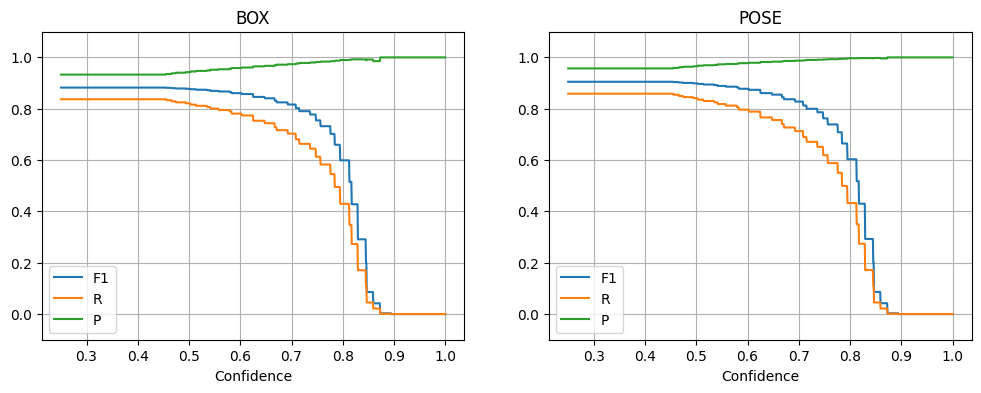

In [42]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    True
)

In [43]:
args["data"] = ALGOTEST_PTH

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/algotest.cache... 9572 images, 559 backgrounds, 0 corrupt: 100%|██████████| 9572/9572 [00:00<?, ?it/s]
tst validation:   0%|          | 0/75 [00:00<?, ?it/s]

tst validation: 100%|██████████| 75/75 [05:46<00:00,  4.62s/it]


                   all       9572      51930      0.934      0.832      0.891      0.585      0.949      0.846      0.906      0.903
   task    F1     P     R  MAP@50
0   box 0.880 0.934 0.832   0.891
1  pose 0.894 0.949 0.846   0.906


In [44]:
args["data"] = PG2

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]


tst validation: 100%|██████████| 2/2 [00:07<00:00,  3.60s/it]


                   all        191        417      0.918      0.484      0.714      0.455      0.945      0.499      0.732      0.719
   task    F1     P     R  MAP@50
0   box 0.634 0.918 0.484   0.714
1  pose 0.653 0.945 0.499   0.732


In [45]:
args["data"] = PG2_PROCESSED

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15_nn/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]


tst validation: 100%|██████████| 2/2 [00:07<00:00,  3.60s/it]


                   all        191        417      0.782      0.645      0.764      0.433      0.817      0.674       0.79      0.781
   task    F1     P     R  MAP@50
0   box 0.707 0.782 0.645   0.764
1  pose 0.739 0.817 0.674   0.790


In [33]:
inferer_adapter = TFLiteInferenceWithInputAdapter(
    yolo_pth=os.path.join(BASE_WEIGHTS_PTH, "weights/best_saved_model/best_full_integer_quant.tflite"),
    head_pth=os.path.join(BASE_WEIGHTS_PTH, "weights/head_saved_model/head_float32.tflite"),
    adapter_pth="input_adapter/input_adapter_full_integer_quant.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

In [34]:
args["data"] = PG2

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer_adapter, args),
    False,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]


tst validation: 100%|██████████| 2/2 [00:08<00:00,  4.32s/it]


                   all        191        417      0.898      0.674      0.811      0.494       0.93      0.698      0.832      0.827
   task    F1     P     R  MAP@50
0   box 0.770 0.898 0.674   0.811
1  pose 0.797 0.930 0.698   0.832
